In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [2]:
# STEP 1: LOAD DATASET
DATA_PATH = "AI_Resume_Screening.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Keep AI_Resume_Screening.csv in the same folder as this Python file."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("AI RESUME SCREENING - DATASET LOADED")
print("=" * 70)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

AI RESUME SCREENING - DATASET LOADED
Shape: (1000, 11)

Columns:
['Resume_ID', 'Name', 'Skills', 'Experience (Years)', 'Education', 'Certifications', 'Job Role', 'Recruiter Decision', 'Salary Expectation ($)', 'Projects Count', 'AI Score (0-100)']


In [3]:
# STEP 2: INITIAL DATA INSPECTION
print("\n" + "=" * 70)
print("STEP 2 - INITIAL DATA INSPECTION")
print("=" * 70)

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


STEP 2 - INITIAL DATA INSPECTION

First 5 rows:
   Resume_ID              Name                                        Skills  \
0          1        Ashley Ali                      TensorFlow, NLP, Pytorch   
1          2      Wesley Roman  Deep Learning, Machine Learning, Python, SQL   
2          3     Corey Sanchez         Ethical Hacking, Cybersecurity, Linux   
3          4  Elizabeth Carney                   Python, Pytorch, TensorFlow   
4          5        Julie Hill                              SQL, React, Java   

   Experience (Years) Education                Certifications  \
0                  10      B.Sc                           NaN   
1                  10       MBA                     Google ML   
2                   1       MBA  Deep Learning Specialization   
3                   7    B.Tech                 AWS Certified   
4                   4       PhD                           NaN   

                Job Role Recruiter Decision  Salary Expectation ($)  \
0       


STEP 3 - TARGET VARIABLE ANALYSIS
Recruiter Decision
Hire      812
Reject    188
Name: count, dtype: int64

Target percentage:
Recruiter Decision
Hire      81.2
Reject    18.8
Name: proportion, dtype: float64


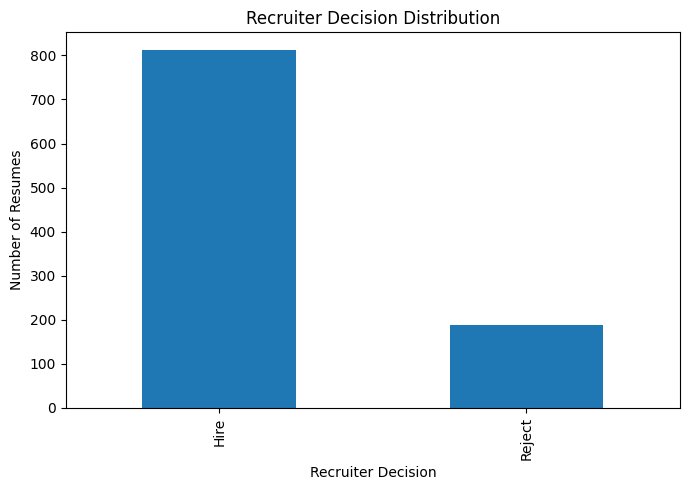

In [4]:
# STEP 3: TARGET ANALYSIS
TARGET = "Recruiter Decision"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found in dataset.")

print("\n" + "=" * 70)
print("STEP 3 - TARGET VARIABLE ANALYSIS")
print("=" * 70)

print(df[TARGET].value_counts())
print("\nTarget percentage:")
print(df[TARGET].value_counts(normalize=True).mul(100).round(2))

plt.figure(figsize=(7, 5))
df[TARGET].value_counts().plot(kind="bar")
plt.title("Recruiter Decision Distribution")
plt.xlabel("Recruiter Decision")
plt.ylabel("Number of Resumes")
plt.tight_layout()
plt.show()

In [5]:
# STEP 4: DATA CLEANING
print("\n" + "=" * 70)
print("STEP 4 - DATA QUALITY CLEANING")
print("=" * 70)

df_clean = df.copy()

# Remove exact duplicate rows.
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Clean text columns.
text_columns = ["Skills", "Education", "Certifications", "Job Role", TARGET]
for col in text_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("Unknown").astype(str).str.strip()

# Numeric missing values are handled later by imputers.
print("Shape after duplicate removal:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())


STEP 4 - DATA QUALITY CLEANING
Shape after duplicate removal: (1000, 11)
Remaining duplicates: 0


In [7]:
# STEP 5: FEATURE ENGINEERING
print("\n" + "=" * 70)
print("STEP 5 - FEATURE ENGINEERING")
print("=" * 70)


def add_resume_features(data):
    """Create resume-specific features used by training and prediction."""
    data = data.copy()

    # Number of listed skills.
    data["skill_count"] = (
        data["Skills"]
        .fillna("")
        .astype(str)
        .apply(
            lambda x: 0 if not x.strip()
            else len([s for s in x.split(",") if s.strip()])
        )
    )

    # Whether a certification is available.
    data["has_certification"] = (
        data["Certifications"]
        .fillna("Unknown")
        .astype(str)
        .str.lower()
        .isin(["unknown", "nan", "none", ""])
        .eq(False)
        .astype(int)
    )

    # Projects per year of experience.
    data["projects_per_experience"] = (
        data["Projects Count"] /
        data["Experience (Years)"].replace(0, np.nan)
    )

    # Salary expectation relative to experience.
    data["salary_per_experience"] = (
        data["Salary Expectation ($)"] /
        data["Experience (Years)"].replace(0, np.nan)
    )

    # Remove identifiers from model input.
    data = data.drop(
        columns=["Resume_ID", "Name"],
        errors="ignore"
    )

    return data


X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET].map({"Reject": 0, "Hire": 1})

if y.isna().any():
    raise ValueError(
        "Target contains values other than 'Hire' and 'Reject'. "
        f"Found: {df_clean[TARGET].unique().tolist()}"
    )

X_fe = add_resume_features(X)

print("Original feature count:", X.shape[1])
print("Feature count after engineering:", X_fe.shape[1])

print("\nNew engineered features:")
print([
    "skill_count",
    "has_certification",
    "projects_per_experience",
    "salary_per_experience",
])


STEP 5 - FEATURE ENGINEERING
Original feature count: 10
Feature count after engineering: 12

New engineered features:
['skill_count', 'has_certification', 'projects_per_experience', 'salary_per_experience']


In [8]:
# STEP 6: TRAIN / TEST SPLIT
print("\n" + "=" * 70)
print("STEP 6 - TRAIN / TEST SPLIT")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X_fe,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


STEP 6 - TRAIN / TEST SPLIT
Training rows: 800
Testing rows: 200

Training target distribution:
Recruiter Decision
1    650
0    150
Name: count, dtype: int64

Testing target distribution:
Recruiter Decision
1    162
0     38
Name: count, dtype: int64


In [9]:
# STEP 7: PREPROCESSING

print("\n" + "=" * 70)
print("STEP 7 - PREPROCESSING")
print("=" * 70)

# Text feature: TF-IDF on Skills.
skills_transformer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=300,
    sublinear_tf=True
)

numerical_features = [
    "Experience (Years)",
    "Salary Expectation ($)",
    "Projects Count",
    "skill_count",
    "has_certification",
    "projects_per_experience",
    "salary_per_experience",
]

categorical_features = [
    "Education",
    "Certifications",
    "Job Role"
]

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("skills", skills_transformer, "Skills"),
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("TF-IDF features:", "Skills")
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)


STEP 7 - PREPROCESSING
TF-IDF features: Skills
Numerical features: ['Experience (Years)', 'Salary Expectation ($)', 'Projects Count', 'skill_count', 'has_certification', 'projects_per_experience', 'salary_per_experience']
Categorical features: ['Education', 'Certifications', 'Job Role']


In [11]:
# STEP 8: MODEL DEFINITIONS
print("\n" + "=" * 70)
print("STEP 8 - MODEL DEFINITIONS")
print("=" * 70)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

for name in models:
    print("-", name)


STEP 8 - MODEL DEFINITIONS
- Logistic Regression
- Random Forest
- XGBoost


In [13]:
# STEP 9: CROSS-VALIDATION + SMOTE MODEL COMPARISON
print("\n" + "=" * 70)
print("STEP 9 - MODEL COMPARISON")
print("=" * 70)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, model in models.items():
    for use_smote in [False, True]:

        steps = [
            ("preprocessor", preprocessor)
        ]

        if use_smote:
            steps.append(
                ("smote", SMOTE(random_state=42))
            )

        steps.append(
            ("classifier", model)
        )

        pipeline = ImbPipeline(steps=steps)

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,
            return_train_score=False
        )

        cv_results.append({
            "Model": model_name,
            "SMOTE": use_smote,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1-score": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean()
        })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

print("\nCross-validation results:")
print(cv_results_df.round(4).to_string(index=False))


STEP 9 - MODEL COMPARISON

Cross-validation results:
              Model  SMOTE  Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression  False    0.9788     0.9822  0.9923    0.9871   0.9989
Logistic Regression   True    0.9788     1.0000  0.9738    0.9867   0.9989
            XGBoost   True    0.9762     0.9847  0.9862    0.9854   0.9969
            XGBoost  False    0.9738     0.9802  0.9877    0.9839   0.9968
      Random Forest   True    0.9538     0.9681  0.9754    0.9716   0.9853
      Random Forest  False    0.9500     0.9528  0.9877    0.9698   0.9898


In [14]:
# STEP 10: FINAL XGBOOST MODEL
print("\n" + "=" * 70)
print("STEP 10 - FINAL XGBOOST TRAINING")
print("=" * 70)

final_model = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

final_model.fit(X_train, y_train)

print("XGBoost model trained successfully.")



STEP 10 - FINAL XGBOOST TRAINING
XGBoost model trained successfully.


In [15]:
# STEP 11: FINAL TEST EVALUATION
print("\n" + "=" * 70)
print("STEP 11 - FINAL TEST SET EVALUATION")
print("=" * 70)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

for metric, score in final_metrics.items():
    print(f"{metric:10s}: {score:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Reject", "Hire"],
        zero_division=0
    )
)


STEP 11 - FINAL TEST SET EVALUATION
Accuracy  : 0.9700
Precision : 0.9875
Recall    : 0.9753
F1-score  : 0.9814
ROC-AUC   : 0.9956

Classification Report:
              precision    recall  f1-score   support

      Reject       0.90      0.95      0.92        38
        Hire       0.99      0.98      0.98       162

    accuracy                           0.97       200
   macro avg       0.94      0.96      0.95       200
weighted avg       0.97      0.97      0.97       200



Confusion Matrix:
[[ 36   2]
 [  4 158]]


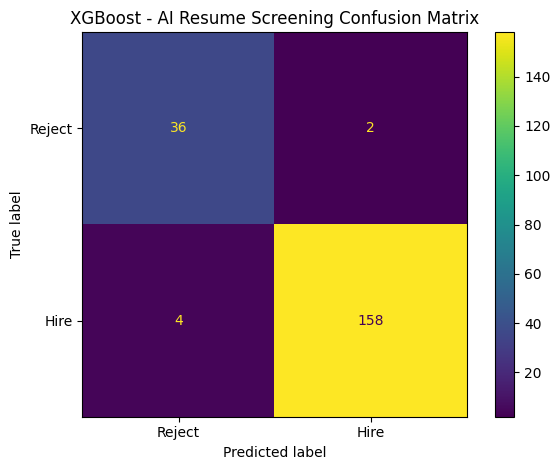

In [16]:
# STEP 12: CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Reject", "Hire"]
)

disp.plot(values_format="d")
plt.title("XGBoost - AI Resume Screening Confusion Matrix")
plt.tight_layout()
plt.show()


In [17]:
# STEP 13: ROC CURVE

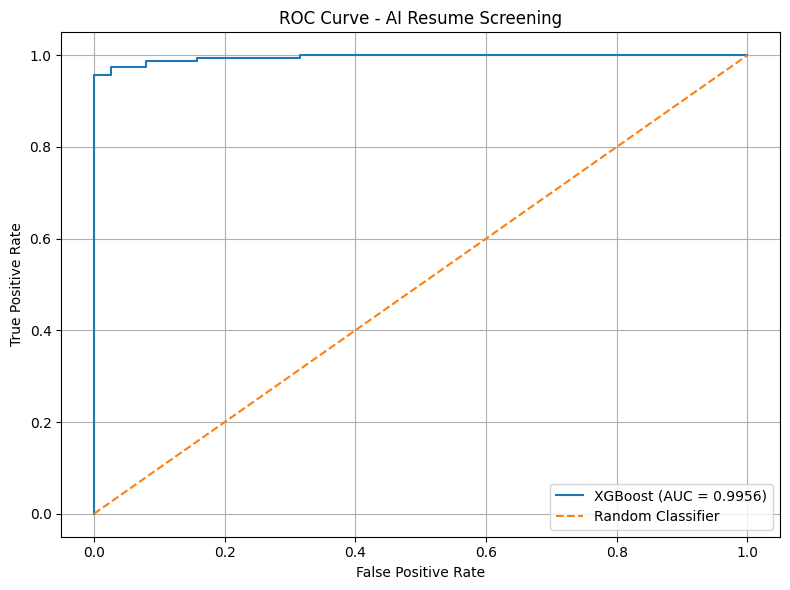

In [18]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.4f})"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - AI Resume Screening")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


STEP 14 - FEATURE IMPORTANCE

Top 20 important features:
                            Feature  Importance
            num__Experience (Years)    0.180957
                skills__python deep    0.076185
                num__Projects Count    0.053364
       num__projects_per_experience    0.053296
        skills__linux cybersecurity    0.050534
         num__salary_per_experience    0.031985
         skills__pytorch tensorflow    0.028528
      skills__cybersecurity ethical    0.028430
                skills__sql machine    0.026397
         skills__hacking networking    0.024904
             skills__tensorflow nlp    0.023680
            skills__ethical hacking    0.022285
             skills__python pytorch    0.021279
                 skills__networking    0.017346
                    skills__pytorch    0.016195
        skills__cybersecurity linux    0.015014
cat__Job Role_Cybersecurity Analyst    0.013250
                 skills__python sql    0.013130
      cat__Certifications_Goog

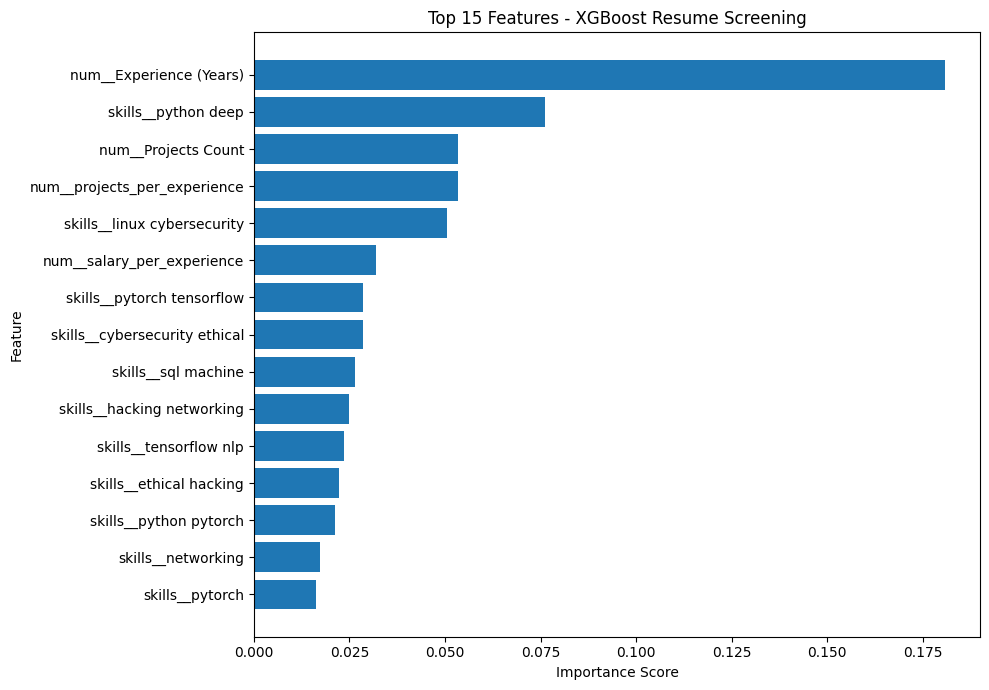

In [19]:
# STEP 14: FEATURE IMPORTANCE
print("\n" + "=" * 70)
print("STEP 14 - FEATURE IMPORTANCE")
print("=" * 70)

xgb_model = final_model.named_steps["classifier"]

feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 20 important features:")
print(importance_df.head(20).to_string(index=False))

top_features = (
    importance_df
    .head(15)
    .sort_values(by="Importance", ascending=True)
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 15 Features - XGBoost Resume Screening")
plt.tight_layout()
plt.show()


In [20]:
# STEP 15: SAVE MODEL
print("\n" + "=" * 70)
print("STEP 15 - SAVE TRAINED MODEL")
print("=" * 70)

ARTIFACT_DIR = "resume_screening_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    ARTIFACT_DIR,
    "ai_resume_screening_xgboost_pipeline.pkl"
)

RESULTS_PATH = os.path.join(
    ARTIFACT_DIR,
    "model_comparison_results.csv"
)

IMPORTANCE_PATH = os.path.join(
    ARTIFACT_DIR,
    "feature_importance.csv"
)

joblib.dump(final_model, MODEL_PATH)
cv_results_df.to_csv(RESULTS_PATH, index=False)
importance_df.to_csv(IMPORTANCE_PATH, index=False)

print("Model saved:", MODEL_PATH)
print("Comparison saved:", RESULTS_PATH)
print("Feature importance saved:", IMPORTANCE_PATH)


STEP 15 - SAVE TRAINED MODEL
Model saved: resume_screening_artifacts/ai_resume_screening_xgboost_pipeline.pkl
Comparison saved: resume_screening_artifacts/model_comparison_results.csv
Feature importance saved: resume_screening_artifacts/feature_importance.csv


In [21]:
# STEP 16: PREDICTION FUNCTION FOR A NEW RESUME
def predict_resume(resume_data, model=final_model):
    """
    Predict whether a new resume is likely to be shortlisted.

    Required input keys:
        Skills
        Experience (Years)
        Education
        Certifications
        Job Role
        Salary Expectation ($)
        Projects Count
        AI Score (0-100)

    Resume_ID and Name are optional and ignored by the model.
    """

    required_fields = [
        "Skills",
        "Experience (Years)",
        "Education",
        "Certifications",
        "Job Role",
        "Salary Expectation ($)",
        "Projects Count",
    ]

    missing = [
        field for field in required_fields
        if field not in resume_data
    ]

    if missing:
        raise ValueError(
            "Missing required fields: " + ", ".join(missing)
        )

    applicant_df = pd.DataFrame([resume_data])

    applicant_df = add_resume_features(applicant_df)

    probability_hire = model.predict_proba(
        applicant_df
    )[0, 1]

    prediction = int(
        model.predict(applicant_df)[0]
    )

    decision = "Hire / Shortlist" if prediction == 1 else "Reject / Not Shortlist"

    return {
        "hire_probability": round(
            float(probability_hire) * 100,
            2
        ),
        "decision": decision
    }


In [22]:
sample_resume = {
    "Skills": "Python, Machine Learning, Deep Learning, SQL, TensorFlow",
    "Experience (Years)": 3,
    "Education": "B.Tech",
    "Certifications": "Google ML",
    "Job Role": "Data Scientist",
    "Salary Expectation ($)": 70000,
    "Projects Count": 6,
}

prediction = predict_resume(sample_resume)

print("\n" + "=" * 70)
print("SAMPLE RESUME SCREENING")
print("=" * 70)
print("Hire Probability:", str(prediction["hire_probability"]) + "%")
print("Decision:", prediction["decision"])



SAMPLE RESUME SCREENING
Hire Probability: 99.88%
Decision: Hire / Shortlist


In [23]:
# STEP 17: SAMPLE PREDICTION
sample_resume = {
    "Skills": "Python, Machine Learning, Deep Learning, SQL, TensorFlow",
    "Experience (Years)": 3,
    "Education": "B.Tech",
    "Certifications": "Google ML",
    "Job Role": "Data Scientist",
    "Salary Expectation ($)": 70000,
    "Projects Count": 6,
}

prediction = predict_resume(sample_resume)

print("\n" + "=" * 70)
print("SAMPLE RESUME SCREENING")
print("=" * 70)
print("Hire Probability:", str(prediction["hire_probability"]) + "%")
print("Decision:", prediction["decision"])



SAMPLE RESUME SCREENING
Hire Probability: 99.88%
Decision: Hire / Shortlist
